# Import Libraries

In [1]:
import warnings
warnings.filterwarnings("ignore")
from sklearnex import patch_sklearn
patch_sklearn()

Intel(R) Extension for Scikit-learn* enabled (https://github.com/intel/scikit-learn-intelex)


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn
import seaborn as sns

# linear svc

In [3]:
TrainFeatures = pd.read_csv('X_train_scaled_balanced.csv',header='infer')
TestFeatures = pd.read_csv('X_test_scaled.csv',header='infer')

TrainOutcome = pd.read_csv('y_train_balanced.csv',header='infer')
TestOutcome = pd.read_csv('y_test.csv',header='infer')

In [4]:
TrainOutcome

,Diabetes
0,0
1,0
2,0
3,0
4,0
...,...
372255,1
372256,1
372257,1
372258,1


In [5]:
print(TrainOutcome['Diabetes'].value_counts())
print(TestOutcome['Diabetes'].value_counts())

Diabetes
0    186130
1    186130
Name: count, dtype: int64
Diabetes
0    79828
1    12805
Name: count, dtype: int64


# class countplot for cheking imbalance data and data volume

Train outcome class count


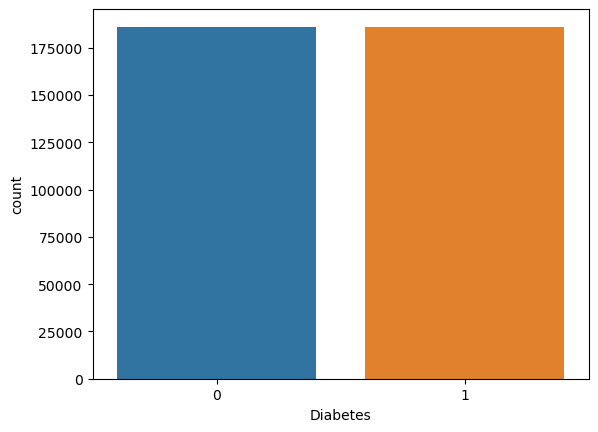

In [6]:
sns.countplot(x ='Diabetes', data = TrainOutcome)
print("Train outcome class count")
# Show the plot
plt.show()

test outcome class count


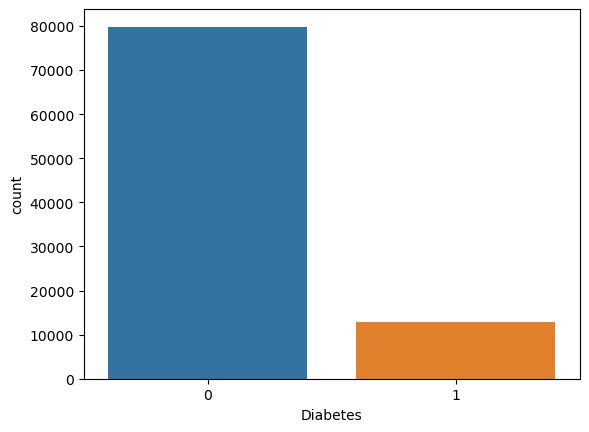

In [7]:
sns.countplot(x ='Diabetes', data = TestOutcome)
print("test outcome class count")
# Show the plot
plt.show()

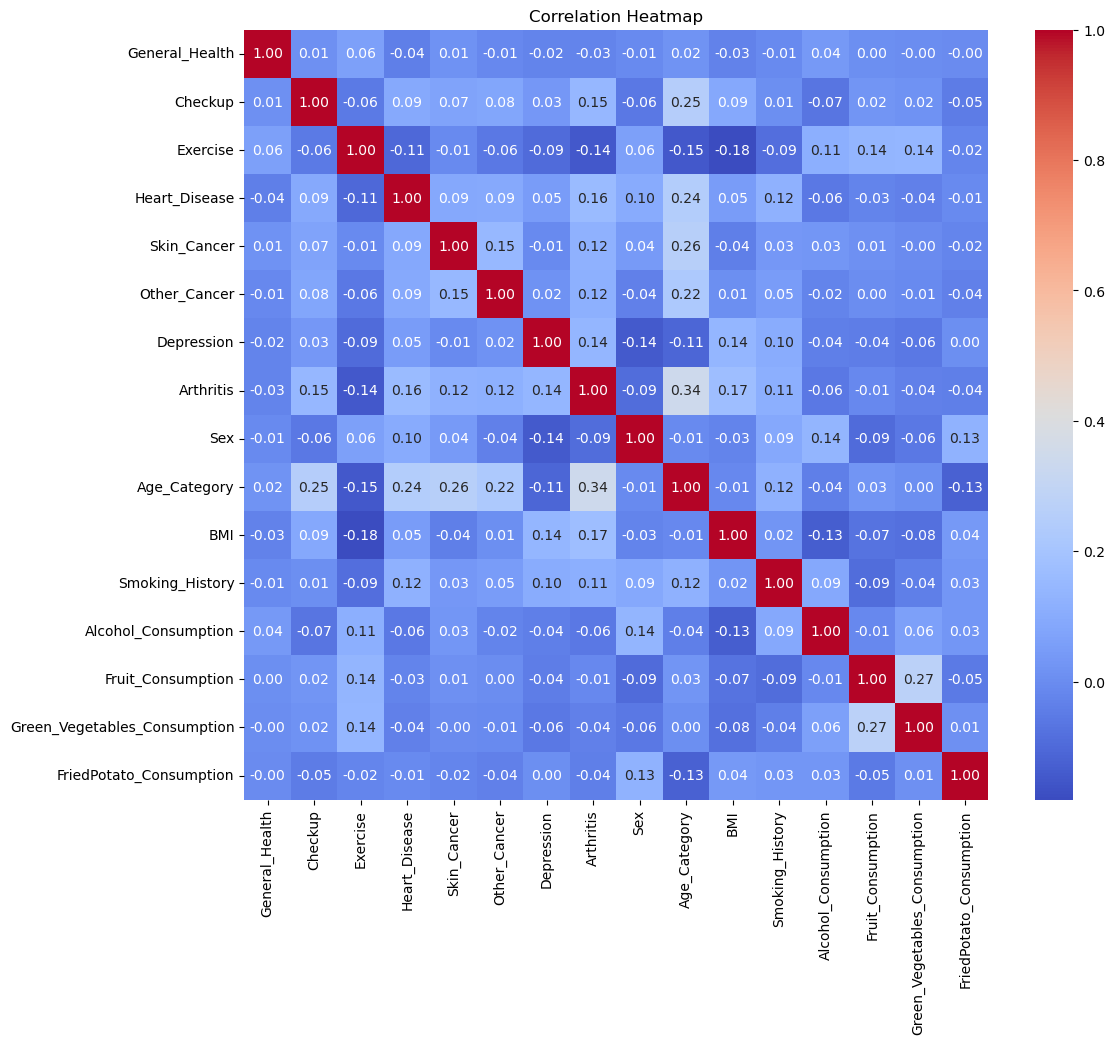

In [8]:
# Calculate the correlation matrix for Data
correlation_matrix = TrainFeatures .corr()
# Create a heatmap
plt.figure(figsize=(12, 10))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

In [9]:
from sklearn.svm import LinearSVC
from sklearn import svm
import sklearn.model_selection as model_selection
from sklearn.metrics import accuracy_score
from sklearn.metrics import f1_score

# default linear svc hyperparameter on data

(372260, 16)
(92633, 16)


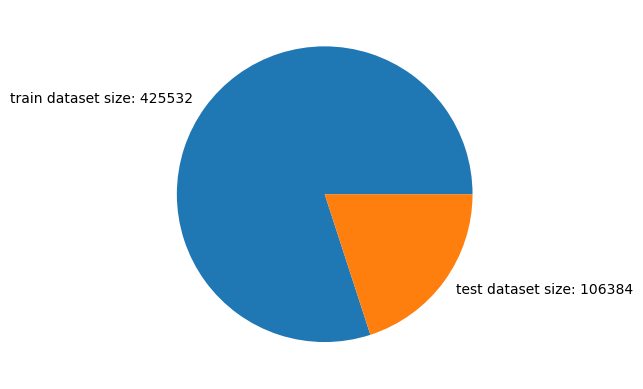

In [10]:
print (TrainFeatures.shape)
print (TestFeatures.shape)
ychart = np.array([425532, 106384])
mylabels = ["train dataset size: 425532", "test dataset size: 106384"]
plt.pie(ychart, labels = mylabels)
plt.show() 

# hyperparameter : class sklearn.svm.LinearSVC(penalty='l2', loss='squared_hinge', *, dual='auto', tol=0.0001, C=1.0, multi_class='ovr', fit_intercept=True, intercept_scaling=1, class_weight=None, verbose=0, random_state=None, max_iter=1000)

In [11]:
X_train= TrainFeatures 
y_train=TrainOutcome 
X_test= TestFeatures 
y_test=TestOutcome 
lsvc = LinearSVC(verbose=0)
lsvc.fit(X_train, y_train)
score = lsvc.score(X_train, y_train)
print("Score: ", score)

Score:  0.716364906248321


In [12]:
y_pred = lsvc.predict(X_test)
print("svm Accuracy:", accuracy_score(y_test, y_pred))

svm Accuracy: 0.6881348979305432


In [13]:
X_train

,General_Health,Checkup,Exercise,Heart_Disease,Skin_Cancer,Other_Cancer,Depression,Arthritis,Sex,Age_Category,BMI,Smoking_History,Alcohol_Consumption,Fruit_Consumption,Green_Vegetables_Consumption,FriedPotato_Consumption
0,0.487756,0.476029,0.540240,3.375623,3.055121,3.055444,1.993437,1.437421,-0.963170,0.699407,-0.223321,1.211069,-0.501129,-0.556653,-0.209552,2.525462
1,-0.181217,0.476029,0.540240,-0.296242,-0.327319,3.055444,-0.501646,-0.695691,-0.963170,0.699407,-0.369131,-0.825717,-0.622927,0.006160,-1.014403,-0.733196
2,1.156730,0.476029,0.540240,-0.296242,-0.327319,-0.327285,-0.501646,-0.695691,1.038239,-0.151524,0.452009,1.211069,0.838653,0.006160,-0.209552,-0.500434
3,1.156730,0.476029,0.540240,-0.296242,3.055121,-0.327285,-0.501646,1.437421,1.038239,0.132119,0.227922,1.211069,0.351459,1.212188,-0.477836,0.197849
4,-0.181217,0.476029,0.540240,-0.296242,3.055121,3.055444,-0.501646,1.437421,1.038239,1.550338,-0.448942,-0.825717,-0.622927,-0.395850,-0.746120,-0.267673
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
372255,-0.850190,0.476029,-1.851029,-0.296242,-0.327319,-0.327285,1.993437,-0.695691,1.038239,0.456566,0.123861,1.211069,-0.622927,-0.234765,-0.976044,-0.068396
372256,-0.181217,0.476029,0.540240,-0.296242,3.055121,-0.327285,-0.501646,1.437421,1.038239,1.499086,0.104457,1.211069,-0.578912,0.006160,-0.258029,-0.500434
372257,-0.022015,0.476029,-1.851029,-0.296242,3.055121,-0.327285,1.993437,1.437421,1.038239,1.118053,0.300430,1.211069,-0.622927,-0.166046,0.454871,-0.622411
372258,-0.181217,0.476029,-1.851029,-0.296242,-0.327319,3.055444,-0.501646,1.437421,-0.963170,0.244915,1.925848,1.211069,-0.622927,-0.313571,-0.395472,-0.197573


In [15]:
cc= [0.0001, 0.001, 0.01, 0.1, 1, 10 ]
for i in cc:
    lsvc = LinearSVC(C=i)
    lsvc.fit(X_train, y_train)
    score = lsvc.score(X_train, y_train)
    print("train acc: ", score)
    print(i)

train acc:  0.716397141782625
0.0001
train acc:  0.7163756514264223
0.001
train acc:  0.7163595336592704
0.01
train acc:  0.7163675925428464
0.1
train acc:  0.7163407295975931
1
train acc:  0.7156879600279374
10


In [18]:
cc= ['l1', 'l2' ]
for i in cc:
    lsvc = LinearSVC(C=0.0001, penalty=i,dual=False)
    lsvc.fit(X_train, y_train)
    score = lsvc.score(X_train, y_train)
    print("train acc: ", score)
    print(i)

train acc:  0.7157389996239187
l1
train acc:  0.7164025143716757
l2


In [19]:
cc= ['hinge', 'squared_hinge']
for i in cc:
    lsvc = LinearSVC(C=0.0001, loss=i)
    lsvc.fit(X_train, y_train)
    score = lsvc.score(X_train, y_train)
    print("train acc: ", score)
    print(i)

train acc:  0.7156960189115135
hinge
train acc:  0.716397141782625
squared_hinge


In [21]:
cc= [False, True]
for i in cc:
    lsvc = LinearSVC(C=0.0001, dual=i)
    lsvc.fit(X_train, y_train)
    score = lsvc.score(X_train, y_train)
    print("train acc: ", score)
    print(i)

train acc:  0.7164025143716757
False
train acc:  0.716397141782625
True


In [22]:
cc= [1000, 5000,10000,15000]
for i in cc:
    lsvc = LinearSVC(C=0.0001, max_iter=i)
    lsvc.fit(X_train, y_train)
    score = lsvc.score(X_train, y_train)
    print("train acc: ", score)
    print(i)

train acc:  0.716397141782625
1000
train acc:  0.716397141782625
5000
train acc:  0.716397141782625
10000
train acc:  0.716397141782625
15000


In [15]:
lsvc = LinearSVC(C=0.1, max_iter=1000,loss='hinge',penalty='l2')
lsvc.fit(X_train, y_train)
score = lsvc.score(X_train, y_train)

print("train acc: ", score)

y_pred = lsvc.predict(X_test)
print("svm test Accuracy:", accuracy_score(y_test, y_pred))

train acc:  0.7165959275774996
svm test Accuracy: 0.6665335247697904


In [27]:
from sklearn.decomposition import PCA
cc=TrainFeatures.columns
#Initiating PCA to reduce dimentions aka features to 3
pca = PCA(n_components=3)
pca.fit(TrainFeatures )
PCA_ds1 = pd.DataFrame(pca.transform(TrainFeatures ), columns=(["col1","col2", "col3"]))
PCA_ds1.describe().T

,count,mean,std,min,25%,50%,75%,max
col1,372260.0,-7.390591e-17,1.488836,-4.266069,-1.146413,-0.192778,0.935425,6.067948
col2,372260.0,1.129966e-17,1.255252,-5.843404,-0.791046,-0.041088,0.801541,6.379521
col3,372260.0,-1.458267e-17,1.190309,-4.998777,-0.851985,-0.040313,0.830702,6.372000


# using pca on normalized dataset

In [28]:
lsvc = LinearSVC(verbose=0)
lsvc.fit(PCA_ds1, y_train)
score = lsvc.score(PCA_ds1, y_train)
print("train acc: ", score)

train acc:  0.6662493955837318


In [16]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import uniform
model = LinearSVC(random_state=42)
# Define hyperparameter distribution
param_dist = {
    'C': [0.0001, 0.001, 0.01, 0.1, 1, 10 ],
}
# Perform random search
random_search = RandomizedSearchCV(estimator=model,
                                   param_distributions=param_dist,
                                   n_iter=1000,
                                   cv=5,
                                   scoring='accuracy',
                                   random_state=42)
random_search.fit(X_train, y_train)
# Report best score and parameters
print(f"Best score: {random_search.best_score_:.3f}")
print(f"Best parameters: {random_search.best_params_}")
# Evaluate on test set
best_model = random_search.best_estimator_
accuracy = best_model.score(X_test, y_test)
print(f"Test set accuracy: {accuracy:.3f}")

Best score: 0.716
Best parameters: {'C': 0.001}
Test set accuracy: 0.688


In [17]:
print(f"Test set accuracy: {accuracy:.5f}")

Test set accuracy: 0.68808


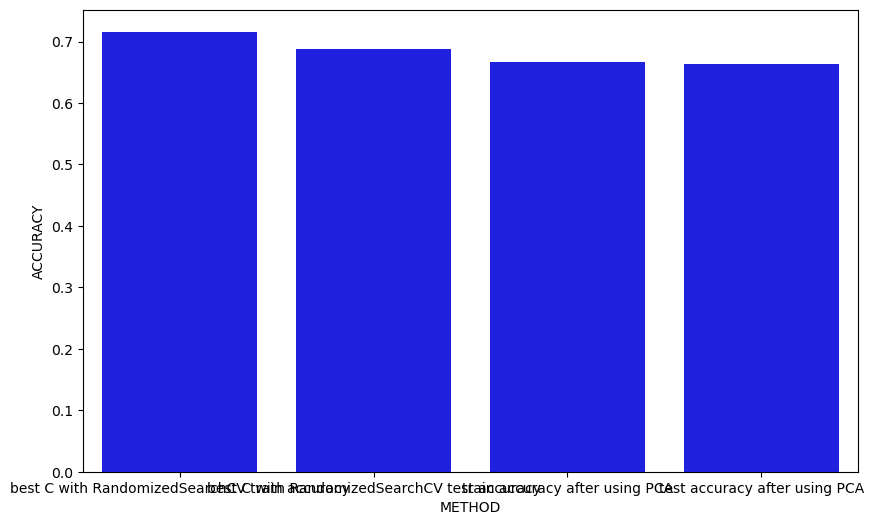

,METHOD,ACCURACY
0,best C with RandomizedSearchCV train accuracy,0.71600
1,best C with RandomizedSearchCV test accuracy,0.68808
2,train accuracy after using PCA,0.66620
3,test accuracy after using PCA,0.66400


In [18]:
scores = [['best C with RandomizedSearchCV train accuracy', 0.716],
          ['best C with RandomizedSearchCV test accuracy', 0.68808],
          ['train accuracy after using PCA', 0.6662],
          ['test accuracy after using PCA', 0.66400]] 


plot_df = pd.DataFrame(scores, columns=['METHOD', 'ACCURACY'])
plt.figure(figsize=(10, 6))
sns.barplot(x='METHOD', y='ACCURACY', data=plot_df,color='blue')
plt.show();

display(plot_df)

In [32]:
# Calculate the correlation matrix for Data
dfN=TrainFeatures 
dfN['class']=TrainOutcome 
dfN

,General_Health,Checkup,Exercise,Heart_Disease,Skin_Cancer,Other_Cancer,Depression,Arthritis,Sex,Age_Category,BMI,Smoking_History,Alcohol_Consumption,Fruit_Consumption,Green_Vegetables_Consumption,FriedPotato_Consumption,class
0,0.487756,0.476029,0.540240,3.375623,3.055121,3.055444,1.993437,1.437421,-0.963170,0.699407,-0.223321,1.211069,-0.501129,-0.556653,-0.209552,2.525462,0
1,-0.181217,0.476029,0.540240,-0.296242,-0.327319,3.055444,-0.501646,-0.695691,-0.963170,0.699407,-0.369131,-0.825717,-0.622927,0.006160,-1.014403,-0.733196,0
2,1.156730,0.476029,0.540240,-0.296242,-0.327319,-0.327285,-0.501646,-0.695691,1.038239,-0.151524,0.452009,1.211069,0.838653,0.006160,-0.209552,-0.500434,0
3,1.156730,0.476029,0.540240,-0.296242,3.055121,-0.327285,-0.501646,1.437421,1.038239,0.132119,0.227922,1.211069,0.351459,1.212188,-0.477836,0.197849,0
4,-0.181217,0.476029,0.540240,-0.296242,3.055121,3.055444,-0.501646,1.437421,1.038239,1.550338,-0.448942,-0.825717,-0.622927,-0.395850,-0.746120,-0.267673,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
372255,-0.850190,0.476029,-1.851029,-0.296242,-0.327319,-0.327285,1.993437,-0.695691,1.038239,0.456566,0.123861,1.211069,-0.622927,-0.234765,-0.976044,-0.068396,1
372256,-0.181217,0.476029,0.540240,-0.296242,3.055121,-0.327285,-0.501646,1.437421,1.038239,1.499086,0.104457,1.211069,-0.578912,0.006160,-0.258029,-0.500434,1
372257,-0.022015,0.476029,-1.851029,-0.296242,3.055121,-0.327285,1.993437,1.437421,1.038239,1.118053,0.300430,1.211069,-0.622927,-0.166046,0.454871,-0.622411,1
372258,-0.181217,0.476029,-1.851029,-0.296242,-0.327319,3.055444,-0.501646,1.437421,-0.963170,0.244915,1.925848,1.211069,-0.622927,-0.313571,-0.395472,-0.197573,1


# show correlation with class

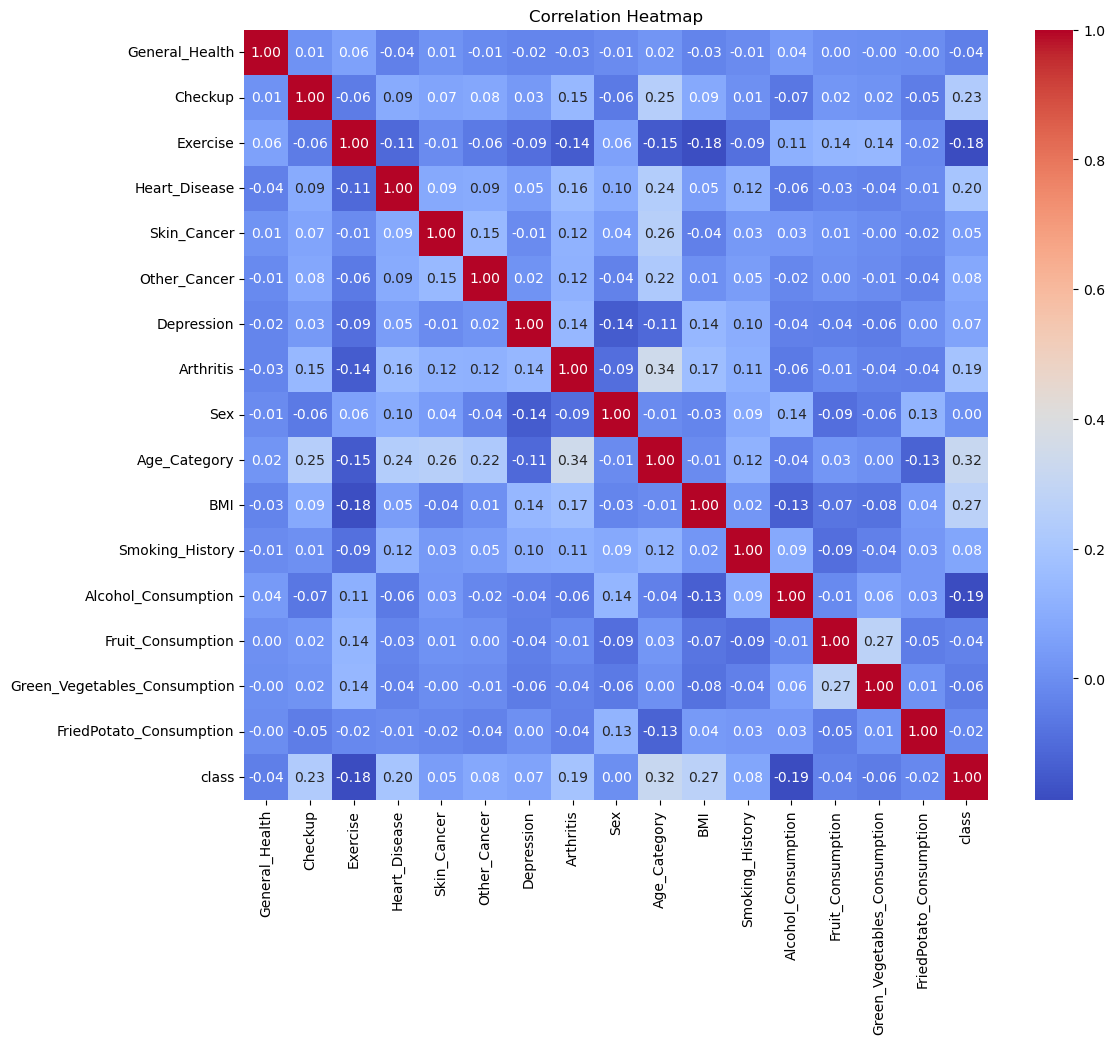

In [20]:
correlation_matrix = dfN.corr()

# Create a heatmap
plt.figure(figsize=(12, 10))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

In [34]:
dfN_encoded = dfN.drop(['FriedPotato_Consumption', 'Green_Vegetables_Consumption','Fruit_Consumption','Sex'], axis=1)

xnew=dfN_encoded.drop('class', axis=1)
ynew=dfN_encoded['class']
X_train5=xnew
y_train5=ynew
TestFeatures = pd.read_csv('X_test_scaled.csv',header='infer')
TestFeatures =TestFeatures.drop(['FriedPotato_Consumption', 'Green_Vegetables_Consumption','Fruit_Consumption','Sex'], axis=1)
x_test5=TestFeatures
y_test5=TestOutcome 
#y_train5 = np.squeeze(y_train5)
lsvc = LinearSVC(verbose=0)
lsvc.fit(X_train5, y_train5)
score = lsvc.score(X_train5, y_train5)
print("train acc: ", score)

y_pred = lsvc.predict(x_test5)
print("svm test Accuracy:", accuracy_score(y_test5, y_pred))

train acc:  0.7150378767528072
svm test Accuracy: 0.6877462675288504


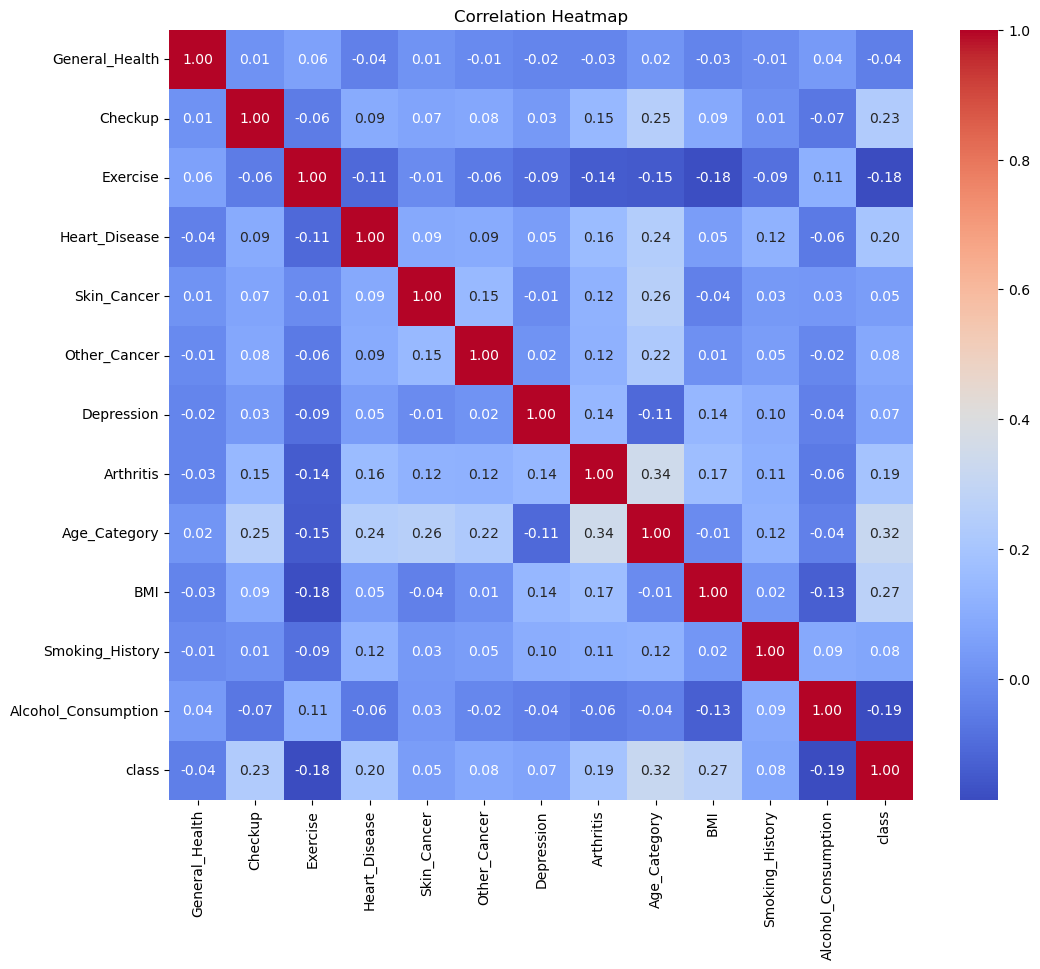

In [35]:
correlation_matrix = dfN_encoded.corr()

# Create a heatmap
plt.figure(figsize=(12, 10))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

In [36]:
dfN_encoded

,General_Health,Checkup,Exercise,Heart_Disease,Skin_Cancer,Other_Cancer,Depression,Arthritis,Age_Category,BMI,Smoking_History,Alcohol_Consumption,class
0,0.487756,0.476029,0.540240,3.375623,3.055121,3.055444,1.993437,1.437421,0.699407,-0.223321,1.211069,-0.501129,0
1,-0.181217,0.476029,0.540240,-0.296242,-0.327319,3.055444,-0.501646,-0.695691,0.699407,-0.369131,-0.825717,-0.622927,0
2,1.156730,0.476029,0.540240,-0.296242,-0.327319,-0.327285,-0.501646,-0.695691,-0.151524,0.452009,1.211069,0.838653,0
3,1.156730,0.476029,0.540240,-0.296242,3.055121,-0.327285,-0.501646,1.437421,0.132119,0.227922,1.211069,0.351459,0
4,-0.181217,0.476029,0.540240,-0.296242,3.055121,3.055444,-0.501646,1.437421,1.550338,-0.448942,-0.825717,-0.622927,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
372255,-0.850190,0.476029,-1.851029,-0.296242,-0.327319,-0.327285,1.993437,-0.695691,0.456566,0.123861,1.211069,-0.622927,1
372256,-0.181217,0.476029,0.540240,-0.296242,3.055121,-0.327285,-0.501646,1.437421,1.499086,0.104457,1.211069,-0.578912,1
372257,-0.022015,0.476029,-1.851029,-0.296242,3.055121,-0.327285,1.993437,1.437421,1.118053,0.300430,1.211069,-0.622927,1
372258,-0.181217,0.476029,-1.851029,-0.296242,-0.327319,3.055444,-0.501646,1.437421,0.244915,1.925848,1.211069,-0.622927,1


In [37]:
dfN_encoded = dfN_encoded.drop(['General_Health', 'Skin_Cancer','Other_Cancer','Depression','Smoking_History'], axis=1)
xnew=dfN_encoded.drop('class', axis=1)
ynew=dfN_encoded['class']
X_train5=xnew
y_train5=ynew
x_test5 =x_test5.drop(['General_Health', 'Skin_Cancer','Other_Cancer','Depression','Smoking_History'], axis=1)

lsvc = LinearSVC(verbose=0)
lsvc.fit(X_train5, y_train5)
score = lsvc.score(X_train5, y_train5)
print("train acc: ", score)

y_pred = lsvc.predict(x_test5)
print("svm test Accuracy:", accuracy_score(y_test5, y_pred))

train acc:  0.7126228979745339
svm test Accuracy: 0.6848207442272193


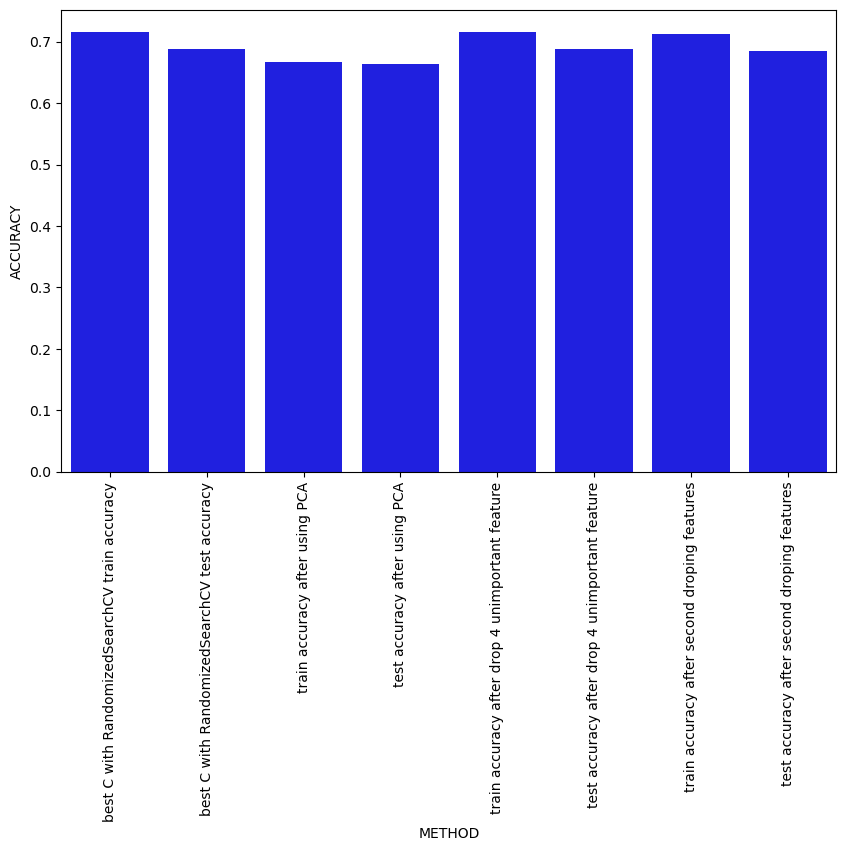

,METHOD,ACCURACY
0,best C with RandomizedSearchCV train accuracy,0.71600
1,best C with RandomizedSearchCV test accuracy,0.68808
2,train accuracy after using PCA,0.66620
3,test accuracy after using PCA,0.66400
4,train accuracy after drop 4 unimportant feature,0.71503
5,test accuracy after drop 4 unimportant feature,0.68774
6,train accuracy after second droping features,0.71262
7,test accuracy after second droping features,0.68482


In [41]:
scores = [['best C with RandomizedSearchCV train accuracy', 0.716],
          ['best C with RandomizedSearchCV test accuracy', 0.68808],
          ['train accuracy after using PCA', 0.6662],
          ['test accuracy after using PCA', 0.66400],
          ['train accuracy after drop 4 unimportant feature', 0.71503],
          ['test accuracy after drop 4 unimportant feature', 0.68774],
          ['train accuracy after second droping features', 0.71262],
          ['test accuracy after second droping features', 0.68482],
         ] 


plot_df = pd.DataFrame(scores, columns=['METHOD', 'ACCURACY'])
plt.figure(figsize=(10, 6))
sns.barplot(x='METHOD', y='ACCURACY', data=plot_df,color='blue')
plt.xticks(rotation='vertical')
plt.show();


display(plot_df)

In [42]:
print('best test accuracy: 0.68808 for Tuned linearSVC by RandomizedSearchCV')

best test accuracy: 0.68808 for Tuned linearSVC by RandomizedSearchCV


In [44]:
TrainFeatures = pd.read_csv('X_train_scaled_balanced.csv',header='infer')
TestFeatures = pd.read_csv('X_test_scaled.csv',header='infer')

TrainOutcome = pd.read_csv('y_train_balanced.csv',header='infer')
TestOutcome = pd.read_csv('y_test.csv',header='infer')
X_train= TrainFeatures 
y_train=TrainOutcome 
X_test= TestFeatures 
y_test=TestOutcome 
lsvc = LinearSVC(C=0.001, max_iter=1000,loss='hinge',penalty='l2')
lsvc.fit(X_train, y_train)
score = lsvc.score(X_train, y_train)
print("train acc: ", score)
y_pred = lsvc.predict(X_test)
print("svm test Accuracy:", accuracy_score(y_test, y_pred))

train acc:  0.716534142803417
svm test Accuracy: 0.6656591063659819


In [45]:
from ISLP import confusion_table
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score, ConfusionMatrixDisplay, classification_report, log_loss
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

[[51742 28086]
 [ 2885  9920]]
              precision    recall  f1-score   support

           0       0.95      0.65      0.77     79828
           1       0.26      0.77      0.39     12805

    accuracy                           0.67     92633
   macro avg       0.60      0.71      0.58     92633
weighted avg       0.85      0.67      0.72     92633



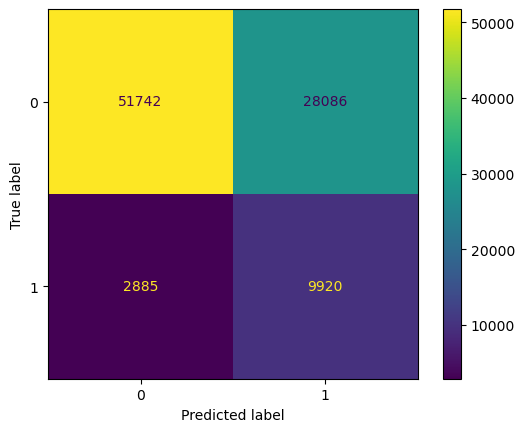

In [46]:
from sklearn import metrics
confusion_matrix=confusion_matrix(y_test, y_pred)
cm_display = metrics.ConfusionMatrixDisplay(confusion_matrix = confusion_matrix, display_labels = [0, 1])

cm_display.plot()
plt.show()

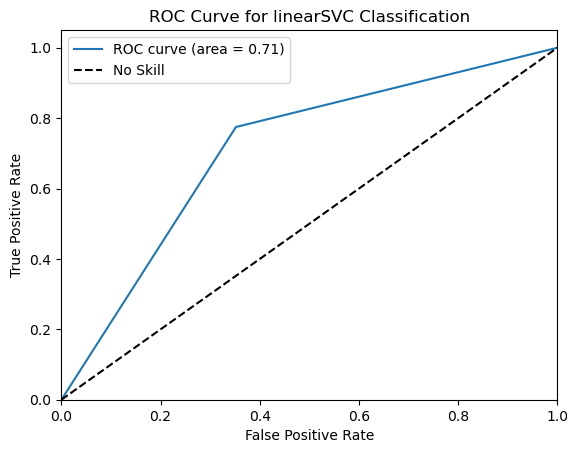

In [47]:
from sklearn.metrics import roc_curve, auc
# Calculate ROC curve
fpr, tpr, thresholds = roc_curve(y_test, y_pred) 
roc_auc = auc(fpr, tpr)
# Plot the ROC curve
plt.figure()  
plt.plot(fpr, tpr, label='ROC curve (area = %0.2f)' % roc_auc)
plt.plot([0, 1], [0, 1], 'k--', label='No Skill')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve for linearSVC Classification')
plt.legend()
plt.show()

In [49]:
# Extract feature coefficients
feature_coefficients = lsvc.coef_
for i, coeff in enumerate(feature_coefficients):
    print(f"Feature {i+1}: {coeff}")

Feature 1: [-0.07923251  0.41920269 -0.12177292  0.12926641 -0.05784015  0.00630911
  0.09645247  0.02415042  0.09699764  0.69122439  0.48843455  0.04986187
 -0.39672799 -0.03019295 -0.03872225  0.02231287]


In [67]:
feature_coefficients=feature_coefficients.T
feature_coefficients[0]

array([-0.07923251,  0.41920269, -0.12177292,  0.12926641, -0.05784015,
        0.00630911,  0.09645247,  0.02415042,  0.09699764,  0.69122439,
        0.48843455,  0.04986187, -0.39672799, -0.03019295, -0.03872225,
        0.02231287])

In [64]:
xxx=X_train.columns
xxx.shape

(16,)

SVC feature importance


Text(0.5, 1.0, 'Feature Importance in SVC')

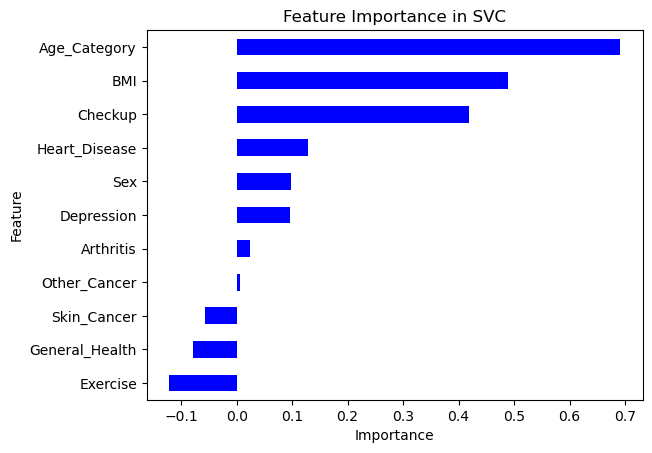

In [69]:
print ("SVC feature importance")
global_importances = pd.Series(feature_coefficients[0], index=xxx)
global_importances=global_importances.iloc[0:11]
global_importances.sort_values(ascending=True, inplace=True)
global_importances.plot.barh(color='blue')
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Feature Importance in SVC")